# Analiza błędów HOG + SVM

Cel: zobaczyć, **gdzie i dlaczego** model HOG + SVM się myli, ze szczególnym uwzględnieniem klasy **Truck** (najniższy recall).

Każdy wycinek dostaje predykcję z walidacji krzyżowej (5 foldów, `StratifiedGroupKFold`), czyli od modelu, który **nie widział zdjęcia źródłowego** tego wycinka. Używamy tylko train + valid, a zbiór testowy pozostaje nieużyty.

Przed uruchomieniem: `python -m src.make_crops` (wycinki w `data/crops/`).

In [1]:
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

from src.config import CROPS_DIR
from src.dataset import load_crops
from src.train import build_hog_model, cross_validate, scores

# JPEG zamiast PNG, żeby siatki zdjęć nie powiększały notatnika do kilku MB
%config InlineBackend.figure_formats = ["jpeg"]


def class_counts(values):
    return {str(name): n for name, n in Counter(values).most_common()}

## Dane

894 wycinków z 556 zdjęć źródłowych
  Ambulance    115  (13%)
  Bus          112  (13%)
  Car          434  (49%)
  Motorcycle   117  (13%)
  Truck        116  (13%)


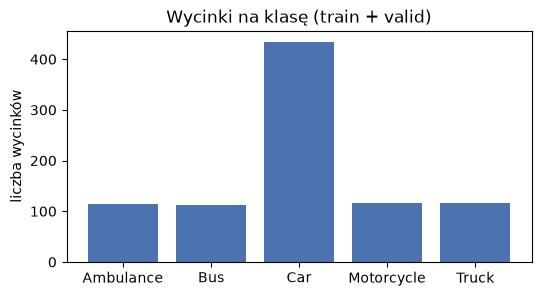

In [2]:
images, labels, groups = load_crops(CROPS_DIR, ("train", "valid"))
labels = np.array(labels)
classes = sorted(set(labels))
counts = Counter(labels)

print(f"{len(images)} wycinków z {len(set(groups))} zdjęć źródłowych")
for c in classes:
    print(f"  {c:<11} {counts[c]:>4}  ({counts[c] / len(labels):.0%})")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(classes, [counts[c] for c in classes], color="#4C72B0")
ax.set_ylabel("liczba wycinków")
ax.set_title("Wycinki na klasę (train + valid)")
plt.show()

## Predykcje z walidacji krzyżowej

Ten sam model HOG + SVM (`build_hog_model`) i protokół co w `python -m src.train`. Trwa około 20 s.

In [3]:
predicted = cross_validate(build_hog_model(), images, labels, groups)

accuracy, macro_f1, recalls = scores(labels, predicted, classes)
print(f"accuracy {accuracy:.3f}   macro F1 {macro_f1:.3f}\n")
print(classification_report(labels, predicted, digits=3, zero_division=0))

accuracy 0.742   macro F1 0.680

              precision    recall  f1-score   support

   Ambulance      0.681     0.670     0.675       115
         Bus      0.658     0.652     0.655       112
         Car      0.799     0.871     0.834       434
  Motorcycle      0.818     0.769     0.793       117
       Truck      0.517     0.388     0.443       116

    accuracy                          0.742       894
   macro avg      0.695     0.670     0.680       894
weighted avg      0.732     0.742     0.735       894



## Macierz pomyłek

Po lewej liczby wycinków, po prawej to samo znormalizowane w wierszach: przekątna to recall klasy, a pozostałe pola pokazują, jaka część danej klasy trafia do innej.

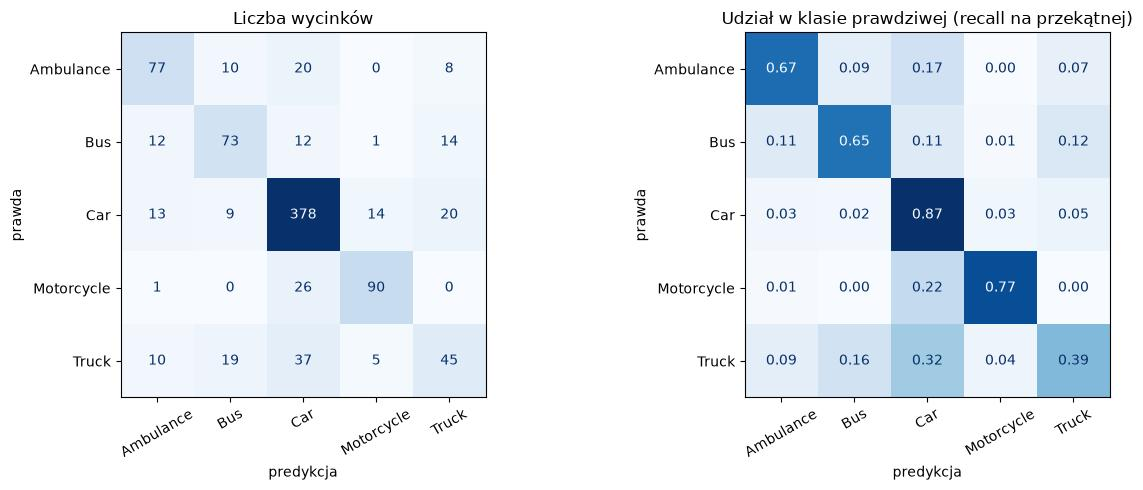

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    labels, predicted, labels=classes, ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Liczba wycinków")
ConfusionMatrixDisplay.from_predictions(
    labels, predicted, labels=classes, normalize="true", values_format=".2f",
    ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title("Udział w klasie prawdziwej (recall na przekątnej)")
for ax in axes:
    ax.set_xlabel("predykcja")
    ax.set_ylabel("prawda")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Najczęstsze pomyłki

In [5]:
matrix = confusion_matrix(labels, predicted, labels=classes)
pairs = [(matrix[i, j], classes[i], classes[j])
         for i in range(len(classes)) for j in range(len(classes)) if i != j and matrix[i, j]]
for n, true, pred in sorted(pairs, reverse=True)[:8]:
    print(f"{true:<11} → {pred:<11} {n:>3}  ({n / counts[true]:.0%} klasy {true})")

Truck       → Car          37  (32% klasy Truck)
Motorcycle  → Car          26  (22% klasy Motorcycle)
Car         → Truck        20  (5% klasy Car)
Ambulance   → Car          20  (17% klasy Ambulance)
Truck       → Bus          19  (16% klasy Truck)
Car         → Motorcycle   14  (3% klasy Car)
Bus         → Truck        14  (12% klasy Bus)
Car         → Ambulance    13  (3% klasy Car)


## Błędnie sklasyfikowane ciężarówki

Wycinki z etykietą **Truck**, które model przypisał do innej klasy. Nad każdym: predykcja i wymiary wycinka.

Błędnie sklasyfikowane ciężarówki: 71 z 116
Jako: {'Car': 37, 'Bus': 19, 'Ambulance': 10, 'Motorcycle': 5}


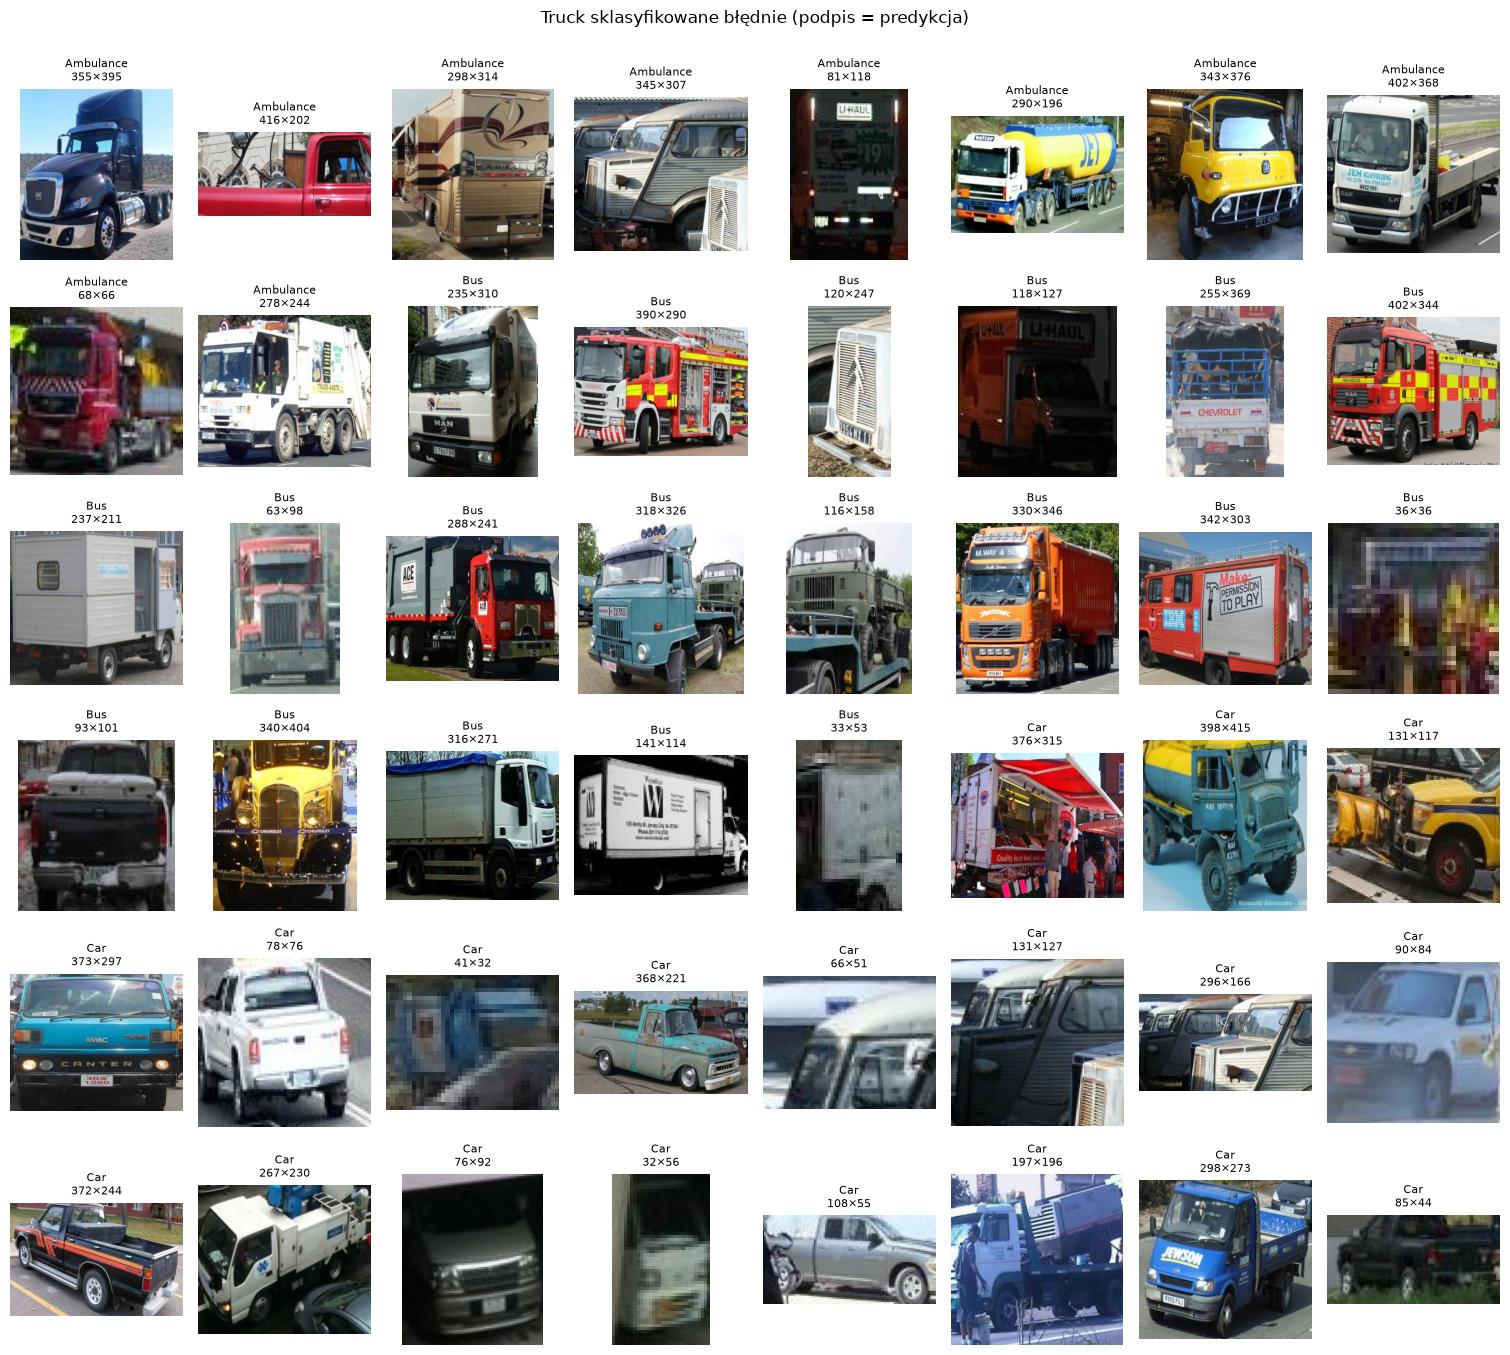

In [6]:
def show_crops(indices, title, columns=8, size=1.9):
    rows = max(1, int(np.ceil(len(indices) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * size, rows * (size + 0.35)))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).ravel(), indices):
        height, width = images[i].shape[:2]
        ax.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        ax.set_title(f"{predicted[i]}\n{width}×{height}", fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout()
    plt.show()


truck_errors = np.flatnonzero((labels == "Truck") & (predicted != "Truck"))
print(f"Błędnie sklasyfikowane ciężarówki: {len(truck_errors)} z {counts['Truck']}")
print("Jako:", class_counts(predicted[truck_errors]))

# Grupujemy według predykcji, żeby łatwiej porównać przykłady
truck_errors = sorted(truck_errors, key=lambda i: predicted[i])
show_crops(truck_errors[:48], "Truck sklasyfikowane błędnie (podpis = predykcja)")

### Dla porównania: ciężarówki rozpoznane poprawnie

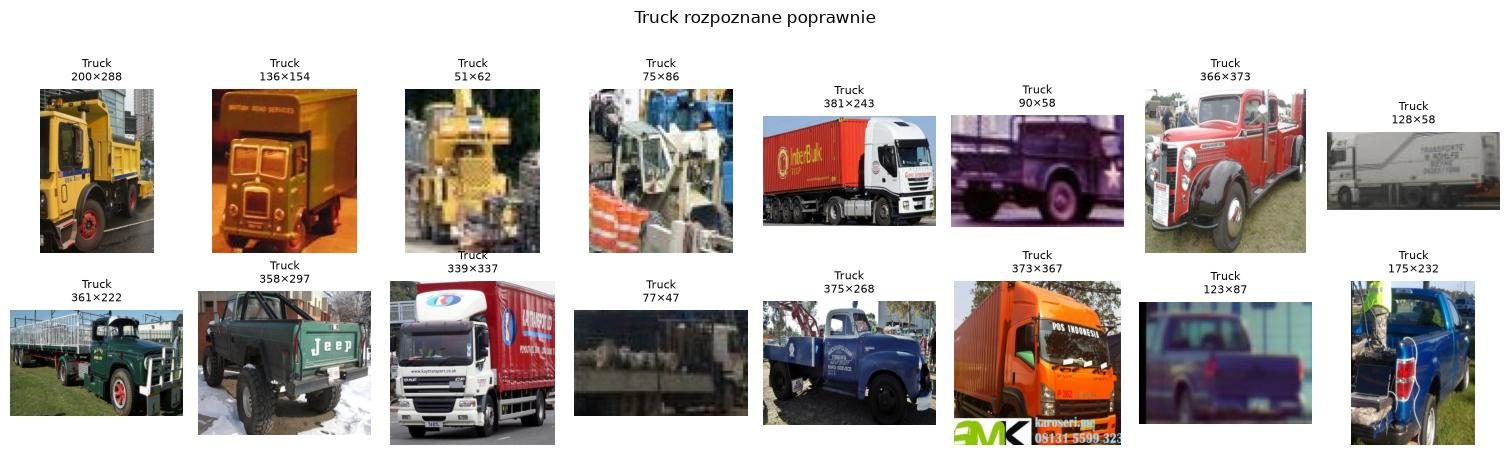

In [7]:
truck_correct = np.flatnonzero((labels == "Truck") & (predicted == "Truck"))
show_crops(truck_correct[:16], "Truck rozpoznane poprawnie")

## Co model bierze za ciężarówkę

Wycinki innych klas, które model przypisał do **Truck** (fałszywe alarmy). Podpis to tu predykcja, czyli zawsze Truck, więc w tytule podajemy prawdziwą klasę.

Fałszywe Truck: 42   {'Car': 20, 'Bus': 14, 'Ambulance': 8}


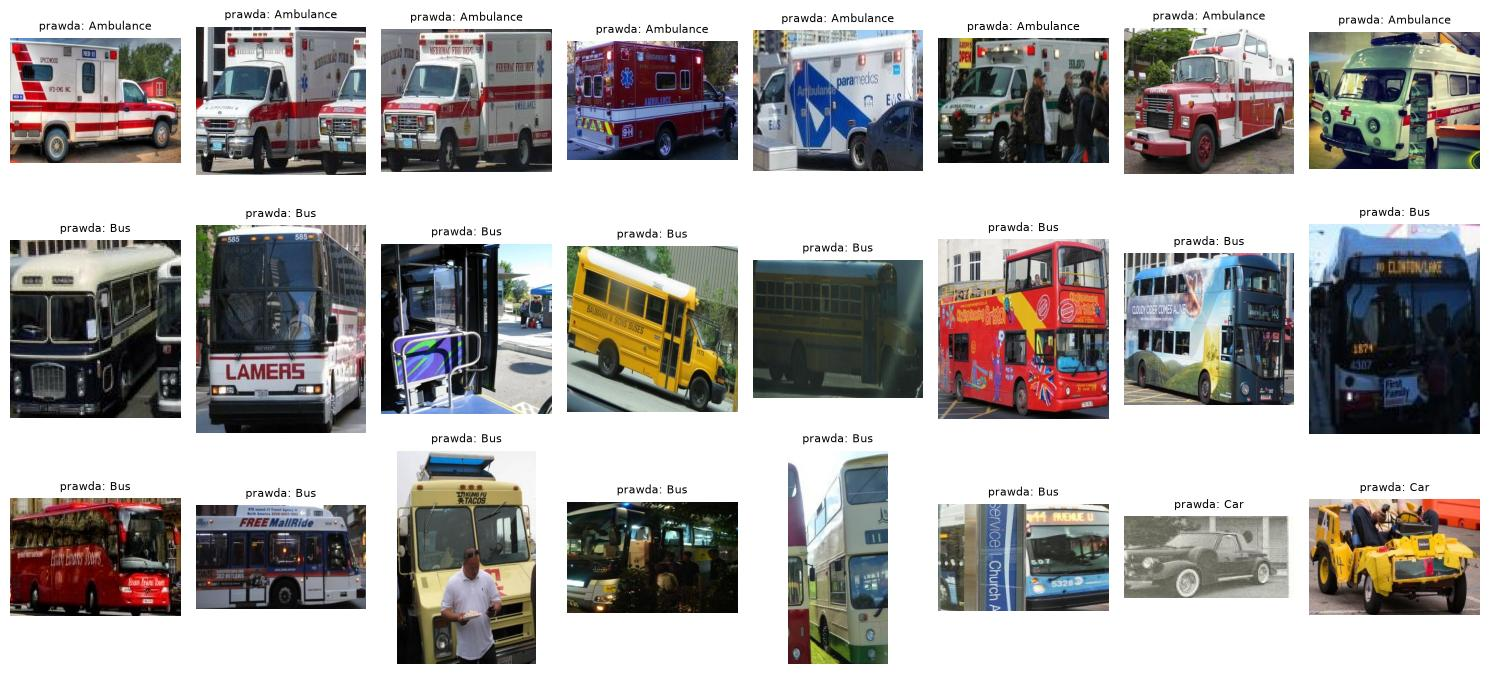

In [8]:
false_trucks = np.flatnonzero((labels != "Truck") & (predicted == "Truck"))
print(f"Fałszywe Truck: {len(false_trucks)}  ", class_counts(labels[false_trucks]))

fig, axes = plt.subplots(int(np.ceil(min(len(false_trucks), 24) / 8)), 8, figsize=(15, 7))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, i in zip(np.atleast_1d(axes).ravel(), sorted(false_trucks, key=lambda i: labels[i])[:24]):
    ax.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    ax.set_title(f"prawda: {labels[i]}", fontsize=8)
plt.tight_layout()
plt.show()

## Czy rozmiar wycinka ma znaczenie?

HOG liczy cechy po przeskalowaniu wycinka do 128×128 px. Mały wycinek po powiększeniu jest rozmyty, więc krawędzie, z których korzysta HOG, są słabsze. Sprawdzamy, czy błędy częściej dotyczą małych wycinków.

krótszy bok [px]   wycinki  accuracy  w tym Truck  recall Truck
32–63                  207      0.78           21          0.43
64–127                 238      0.71           32          0.31
128–255                253      0.76           30          0.43
≥ 256                  196      0.71           33          0.39


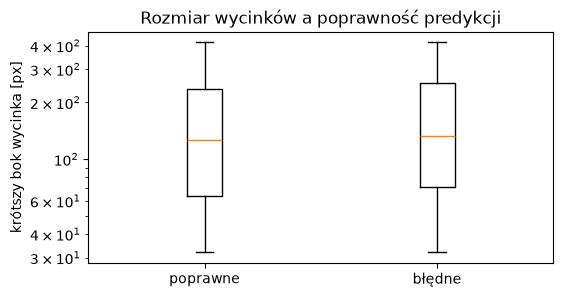

In [9]:
short_side = np.array([min(image.shape[:2]) for image in images])
correct = predicted == labels
bins = [32, 64, 128, 256, 1000]
names = ["32–63", "64–127", "128–255", "≥ 256"]

print(f"{'krótszy bok [px]':<18}{'wycinki':>8}{'accuracy':>10}{'w tym Truck':>13}{'recall Truck':>14}")
for low, high, name in zip(bins[:-1], bins[1:], names):
    in_bin = (short_side >= low) & (short_side < high)
    trucks = in_bin & (labels == "Truck")
    truck_recall = f"{correct[trucks].mean():.2f}" if trucks.any() else "–"
    print(f"{name:<18}{in_bin.sum():>8}{correct[in_bin].mean():>10.2f}{trucks.sum():>13}{truck_recall:>14}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot([short_side[correct], short_side[~correct]], tick_labels=["poprawne", "błędne"])
ax.set_yscale("log")
ax.set_ylabel("krótszy bok wycinka [px]")
ax.set_title("Rozmiar wycinków a poprawność predykcji")
plt.show()

## Wnioski

**1. Truck to najbardziej zróżnicowana klasa.** W tej samej klasie są ciągniki siodłowe, cysterny, śmieciarki, wozy strażackie, kontenerowce, furgony (np. U-Haul), kampery, pickupy i zabytkowe ciężarówki. 116 przykładów to za mało, żeby HOG nauczył się wspólnego wzorca dla tak różnych kształtów. Recall Truck wynosi tylko 0,39 (71 ze 116 błędnie).

**2. Truck → Car (37 wycinków, 32% klasy) to głównie pickupy i małe dostawczaki.** W Open Images pickup ma etykietę Truck, ale jego sylwetka jest bliższa samochodowi osobowemu. Etykiety nie są też spójne: część pickupów model rozpoznaje jako Truck (np. Jeep i niebieski pickup wśród poprawnych przykładów), a część nie. Duża część tego błędu wynika więc z niejednoznacznej definicji klasy, a nie tylko ze słabości modelu.

**3. Truck ↔ Bus (19 i 14 wycinków) to duże, prostokątne pojazdy.** Furgony skrzyniowe, śmieciarki i wozy strażackie mają podobny obrys do autobusu, zwłaszcza widziane z przodu.

**4. Truck ↔ Ambulance (10 i 8 wycinków).** Amerykańskie karetki są budowane na podwoziu ciężarówki z kontenerem z tyłu, więc ich kształt naprawdę przypomina małą ciężarówkę. Wozy strażackie mają z kolei biało-czerwone i żółte pasy jak europejskie karetki. HOG działa jednak na obrazie w skali szarości, więc **kolor**, który mógłby te klasy rozróżnić, w ogóle nie trafia do modelu.

**5. Rozmiar wycinka nie wyjaśnia błędów.** Accuracy we wszystkich przedziałach rozmiaru mieści się w zakresie 0,71–0,78, a recall Truck w 0,31–0,43, bez wyraźnego trendu. Podniesienie progu `MIN_BOX_SIDE` raczej nie pomoże. Pojedyncze błędy dotyczą wycinków bardzo małych albo częściowo zasłoniętych.

**6. Motorcycle → Car (26 wycinków, 22% klasy)** to druga co do wielkości pomyłka. Warto ją przejrzeć tak samo jak ciężarówki.

### Co z tego wynika dla dalszej pracy

- **Zbalansowanie klas raczej nie pomoże Truck.** Truck ma tyle przykładów co Bus, Ambulance i Motorcycle, a SVM już używa `class_weight="balanced"`. Problemem jest zróżnicowanie klasy, a nie liczba przykładów.
- **Cechy koloru** (np. histogram HSV dołączony do HOG) mogą pomóc w parach Ambulance–Truck i Bus–Truck, bo kolor jest dziś całkowicie pomijany.
- **Definicja klasy Truck:** warto ustalić, co robimy z pickupami, i zapisać to w dokumentacji. Opcja z planu awaryjnego karty to „mniej klas”.
- MobileNet + SVM (`src/train.py`) przy `C=1` podnosi recall Truck tylko do 0,59, a pomyłek Truck → Car jest nadal 39. Przy `C=0.3` recall Truck rośnie do 0,68, ale kosztem klasy Car (recall 0,82). To potwierdza, że część problemu leży w samych etykietach.